In [ ]:
!!uv pip install folium
import io
import math
import asyncio
import aiohttp
import numpy as np
from PIL import Image as PILImage
import matplotlib.pyplot as plt
from streetlevel import streetview as streetlevel_streetview
from streetlevel import lookaround
import folium
from IPython.display import display, HTML

# Import the perspective view extraction from our streetview module
import sys
sys.path.insert(0, '.')
from bench_finder.core.streetview import StreetViewClient


('vscode', '2.2.43') to WHOLE


/Users/blackmad/bench_finder/.venv/lib/python3.12/site-packages/term_image/utils.py:749: TermImageWarning: It seems this process is not running within a terminal. Hence, some features will behave differently or be disabled.
See https://term-image.readthedocs.io/en/stable/guide/concepts.html#active-terminal
Any filter for this warning must be set before loading `term_image`, using `UserWarning` with the warning message (since `TermImageWarning` won't be available).
  warnings.warn(


In [2]:
# =============================================================================
# INPUT: Set your latitude and longitude here
# =============================================================================
# INPUT_LAT = 52.36560281265296
# INPUT_LNG =  4.873465022986906


INPUT_LAT = 52.362756
INPUT_LNG = 4.862122


# Choose panorama source: "streetview" or "lookaround"
PANORAMA_SOURCE = "lookaround"  # Options: "streetview" or "lookaround"

# Search radius for finding panorama (meters)
SEARCH_RADIUS = 50

print(f"📍 Input location: ({INPUT_LAT}, {INPUT_LNG})")
print(f"📸 Panorama source: {PANORAMA_SOURCE}")


📍 Input location: (52.362756, 4.862122)
📸 Panorama source: lookaround


In [ ]:
def calculate_bearing(lat1: float, lon1: float, lat2: float, lon2: float) -> float:
    """
    Calculate the bearing (heading) from point 1 to point 2 in degrees.
    
    Args:
        lat1: Latitude of starting point (panorama location)
        lon1: Longitude of starting point (panorama location)
        lat2: Latitude of destination point (input location)
        lon2: Longitude of destination point (input location)
    
    Returns:
        Bearing in degrees (0-360, where 0 is North)
    """
    lat1_rad = math.radians(lat1)
    lat2_rad = math.radians(lat2)
    delta_lon = math.radians(lon2 - lon1)
    
    y = math.sin(delta_lon) * math.cos(lat2_rad)
    x = math.cos(lat1_rad) * math.sin(lat2_rad) - math.sin(lat1_rad) * math.cos(lat2_rad) * math.cos(delta_lon)
    
    bearing = math.atan2(y, x)
    bearing_degrees = math.degrees(bearing)
    
    # Normalize to 0-360
    return (bearing_degrees + 360) % 360


def haversine_distance(lat1: float, lon1: float, lat2: float, lon2: float) -> float:
    """Calculate distance between two points in meters."""
    R = 6371000  # Earth radius in meters
    phi1 = math.radians(lat1)
    phi2 = math.radians(lat2)
    delta_phi = math.radians(lat2 - lat1)
    delta_lambda = math.radians(lon2 - lon1)
    
    a = math.sin(delta_phi/2)**2 + math.cos(phi1) * math.cos(phi2) * math.sin(delta_lambda/2)**2
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1-a))
    
    return R * c


In [ ]:
# =============================================================================
# Fetch the panorama from Google Street View or Apple Lookaround using streetlevel
# =============================================================================

async def fetch_panorama(lat: float, lng: float, source: str = "streetview", radius: int = 50):
    """
    Fetch panorama and metadata from Google Street View or Apple Lookaround.
    
    Args:
        lat: Latitude
        lng: Longitude
        source: "streetview" or "lookaround"
        radius: Search radius in meters
    
    Returns:
        (pano, equirectangular, metadata) tuple
    """
    async with aiohttp.ClientSession() as session:
        if source == "streetview":
            # Find panorama near the location
            pano = await streetlevel_streetview.find_panorama_async(
                lat=lat, lon=lng, radius=100, session=session
            )
            
            if not pano:
                print(f"❌ No Street View panorama found within {radius}m of ({lat}, {lng})")
                return None, None, None

            print(pano)
            print("heading:", pano.heading)
            
            # Get panorama metadata
            pano_lat = pano.lat if hasattr(pano, 'lat') else lat
            pano_lng = pano.lon if hasattr(pano, 'lon') else lng
            pano_id = pano.id if hasattr(pano, 'id') else None
            pano_date = str(pano.date) if hasattr(pano, 'date') else None
            
            metadata = {
                'pano_id': pano_id,
                'lat': pano_lat,
                'lng': pano_lng,
                'date': pano_date,
                'heading': pano.heading if hasattr(pano, 'heading') else None,
                'source': 'streetview',
            }
            
            print(f"✅ Found Street View panorama!")
            print(f"   📍 Panorama location: ({pano_lat:.6f}, {pano_lng:.6f})")
            print(f"   🆔 Pano ID: {pano_id}")
            print(f"   📅 Date: {pano_date}")
            
            # Download the equirectangular panorama
            print("   ⬇️ Downloading panorama tiles...")
            equirectangular = await streetlevel_streetview.get_panorama_async(
                pano, zoom=3, session=session
            )
            
            if equirectangular:
                print(f"   ✅ Downloaded! Size: {equirectangular.size}")
            else:
                print("   ❌ Failed to download panorama")
            
            return pano, equirectangular, metadata
            
        elif source == "lookaround":
            # Get coverage tile
            print("   🔍 Checking Look Around coverage...")
            tile = await lookaround.get_coverage_tile_by_latlon_async(
                lat, lng, session=session
            )
            
            if not tile or not tile.panos or len(tile.panos) == 0:
                print(f"❌ No Look Around coverage found at ({lat}, {lng})")
                return None, None, None
            
            # Find the closest panorama
            closest_pano = None
            min_distance = float('inf')
            for candidate_pano in tile.panos:
                distance = haversine_distance(lat, lng, candidate_pano.lat, candidate_pano.lon)
                if distance < min_distance:
                    min_distance = distance
                    closest_pano = candidate_pano
            
            if closest_pano is None:
                print(f"❌ No closest Look Around panorama found")
                return None, None, None
            
            pano = closest_pano
            pano_lat = pano.lat if hasattr(pano, 'lat') else lat
            pano_lng = pano.lon if hasattr(pano, 'lon') else lng
            pano_id = pano.id if hasattr(pano, 'id') else None
            pano_date = str(pano.date) if hasattr(pano, 'date') else None
            
            metadata = {
                'pano_id': pano_id,
                'lat': pano_lat,
                'lng': pano_lng,
                'date': pano_date,
                'heading': pano.heading if hasattr(pano, 'heading') else None,
                'source': 'lookaround',
            }
            
            print(f"✅ Found Look Around panorama!")
            print(f"   📍 Panorama location: ({pano_lat:.6f}, {pano_lng:.6f})")
            print(f"   🆔 Pano ID: {pano_id}")
            print(f"   📅 Date: {pano_date}")
            
            # Download cubemap faces and convert to equirectangular
            print("   ⬇️ Downloading cubemap faces...")
            auth = lookaround.Authenticator()
            zoom = 2
            
            # Lookaround face indices: BACK=0, LEFT=1, FRONT=2, RIGHT=3, TOP=4, BOTTOM=5
            face_names = ["back", "left", "front", "right", "top", "bottom"]
            face_images = []
            
            try:
                # Try using pillow-heif if available for HEIC support
                try:
                    from pillow_heif import register_heif_opener
                    register_heif_opener()
                except ImportError:
                    pass
                
                for face_idx in range(6):
                    print(f"      Downloading face {face_idx} ({face_names[face_idx]})...")
                    face_heic = await asyncio.to_thread(
                        lookaround.get_panorama_face,
                        pano,
                        face_idx,
                        zoom,
                        auth,
                        None,
                    )
                    img = PILImage.open(io.BytesIO(face_heic))
                    face_images.append(img)
                
                # Convert cubemap to equirectangular using lookaround.to_equirectangular
                # Note: This function is slow (can take 50+ seconds for full resolution)
                # PyTorch must be installed for this to work
                print("   🧵 Converting cubemap to equirectangular...")
                print("      (This may take a while - PyTorch is required)")
                print("      Note: Center of result is inverse direction of travel (looking backwards)")
                
                # Check if camera_metadata is available
                if not hasattr(pano, 'camera_metadata') or pano.camera_metadata is None:
                    print("   ⚠️ Warning: camera_metadata not available, cannot convert to equirectangular")
                    return None, None, None
                
                # Call to_equirectangular - runs in thread since it can be slow
                equirectangular = await asyncio.to_thread(
                    lookaround.to_equirectangular,
                    face_images,
                    pano.camera_metadata
                )
                
                if equirectangular:
                    print(f"   ✅ Converted! Size: {equirectangular.size}")
                else:
                    print("   ❌ Failed to convert cubemap")
                    return None, None, None
                    
            except Exception as e:
                print(f"   ❌ Error fetching/converting Look Around faces: {e}")
                import traceback
                traceback.print_exc()
                return None, None, None
            
            return pano, equirectangular, metadata
        else:
            print(f"❌ Unknown source: {source}. Use 'streetview' or 'lookaround'")
            return None, None, None

# Fetch the panorama
pano, equirectangular, metadata = await fetch_panorama(INPUT_LAT, INPUT_LNG, PANORAMA_SOURCE, 500)


   🔍 Checking Look Around coverage...
✅ Found Look Around panorama!
   📍 Panorama location: (52.362846, 4.862100)
   🆔 Pano ID: 18044057293112774835
   📅 Date: 2022-06-29 09:26:28.787000+00:00
   ⬇️ Downloading cubemap faces...
   🧵 Converting cubemap to equirectangular...
      (This may take a while - PyTorch is required)
      Note: Center of result is inverse direction of travel (looking backwards)
   ✅ Converted! Size: (6416, 3208)


In [5]:
# =============================================================================
# Display map with input location and panorama location
# =============================================================================

if metadata:
    pano_lat = metadata['lat']
    pano_lng = metadata['lng']
    
    # Calculate center point
    center_lat = (INPUT_LAT + pano_lat) / 2
    center_lng = (INPUT_LNG + pano_lng) / 2
    
    # Calculate distance
    distance = haversine_distance(INPUT_LAT, INPUT_LNG, pano_lat, pano_lng)
    
    print(f"📏 Distance between input and panorama: {distance:.1f} meters")
    
    # Create map
    m = folium.Map(location=[center_lat, center_lng], zoom_start=18)
    
    # Add input location marker (red)
    folium.Marker(
        [INPUT_LAT, INPUT_LNG],
        popup=f'Input Location<br>({INPUT_LAT:.6f}, {INPUT_LNG:.6f})',
        icon=folium.Icon(color='red', icon='crosshairs', prefix='fa'),
        tooltip='Input Location'
    ).add_to(m)
    
    # Add panorama location marker (blue)
    folium.Marker(
        [pano_lat, pano_lng],
        popup=f'Panorama Location<br>({pano_lat:.6f}, {pano_lng:.6f})<br>ID: {metadata["pano_id"]}',
        icon=folium.Icon(color='blue', icon='camera', prefix='fa'),
        tooltip='Panorama Location'
    ).add_to(m)
    
    # Add line between the two points
    folium.PolyLine(
        [[INPUT_LAT, INPUT_LNG], [pano_lat, pano_lng]],
        color='purple',
        weight=3,
        opacity=0.7,
        dash_array='10'
    ).add_to(m)
    
    display(HTML("<h3>🗺️ Map: Input Location (red) vs Panorama Location (blue)</h3>"))
    display(m)
else:
    print("No panorama found to display on map.")


📏 Distance between input and panorama: 10.2 meters


In [ ]:
# =============================================================================
# Extract perspective view function (from streetview.py)
# =============================================================================

def extract_perspective_view(
    equirectangular: PILImage.Image,
    heading: float,
    fov: int = 90,
    size: tuple[int, int] = (800, 800),
    panorama_heading_rad: float | None = None,
    source: str = "streetview",
) -> PILImage.Image:
    """
    Extract a perspective view from an equirectangular panorama.
    
    Args:
        equirectangular: The full equirectangular panorama image
        heading: Compass heading in degrees (0-360, where 0 is North) - geographic heading
        fov: Field of view in degrees
        size: Output image size (width, height)
        panorama_heading_rad: The heading of the panorama's center in radians.
            This is the direction the panorama is "facing" (where 0° is North).
            If provided, the heading will be adjusted to account for this offset.
    
    Returns:
        Perspective view image at the specified heading and FOV
    """
    try:
        from equilib import equi2pers
    except ImportError:
        try:
            from pyequilib import equi2pers
        except ImportError:
            print("⚠️ equilib/pyequilib not available, using manual projection")
            return extract_perspective_view_manual(equirectangular, heading, fov, size, panorama_heading_rad)
    
    width, height = size
    
    # Convert PIL Image to numpy array
    equi_array = np.asarray(equirectangular)
    
    # Ensure channel-first format (C, H, W) for equi2pers
    if len(equi_array.shape) == 3 and (equi_array.shape[2] == 3 or equi_array.shape[2] == 4):
        equi_array = np.transpose(equi_array, (2, 0, 1))
    
    # Remove alpha channel if present
    if equi_array.shape[0] == 4:
        equi_array = equi_array[:3, :, :]
    
    # Convert target heading to degrees
    yaw_deg = float(heading)
    
    # Adjust for panorama's heading offset
    # equi2pers uses yaw 0° = East (90° geographic). Heading is geographic CW.
    if panorama_heading_rad is not None:
        pano_heading_deg_raw = np.degrees(panorama_heading_rad)
        if source == "lookaround":
            # Lookaround metadata heading is CCW from North; convert to CW
            pano_heading_deg = (360 - pano_heading_deg_raw) % 360
            # to_equirectangular centers on inverse direction of travel -> add 180
            yaw_deg = (yaw_deg - pano_heading_deg + 90 + 180) % 360
        else:
            pano_heading_deg = pano_heading_deg_raw
            yaw_deg = (yaw_deg - pano_heading_deg + 90) % 360
    else:
        # No panorama heading; still add 90° to align with equi2pers yaw convention
        yaw_deg = (yaw_deg + 90) % 360
    
    # Extract perspective view
    rots_dict = {
        'roll': 0.0,
        'pitch': 0.0,
        'yaw': np.deg2rad(yaw_deg),
    }
    
    pers_img = equi2pers(
        equi=equi_array,
        rots=rots_dict,
        height=height,
        width=width,
        mode='bilinear',
        clip_output=False,
        fov_x=fov,
    )
    
    # Convert back to H, W, C format for PIL
    if len(pers_img.shape) == 3 and pers_img.shape[0] == 3:
        pers_img = np.transpose(pers_img, (1, 2, 0))
    
    pers_img = np.clip(pers_img, 0, 255).astype(np.uint8)
    
    return PILImage.fromarray(pers_img)


def extract_perspective_view_manual(
    equirectangular: PILImage.Image,
    heading: float,
    fov: int,
    size: tuple[int, int],
    panorama_heading_rad: float | None = None,
    source: str = "streetview",
) -> PILImage.Image:
    """Fallback manual extraction method."""
    width, height = size
    pano_width, pano_height = equirectangular.size
    
    fov_rad = np.radians(fov)
    
    # Adjust heading for panorama's heading offset and coordinate system
    adjusted_heading = heading
    if panorama_heading_rad is not None:
        pano_heading_deg_raw = np.degrees(panorama_heading_rad)
        if source == "lookaround":
            pano_heading_deg = (360 - pano_heading_deg_raw) % 360
            adjusted_heading = (heading - pano_heading_deg + 90 + 180) % 360
        else:
            pano_heading_deg = pano_heading_deg_raw
            adjusted_heading = (heading - pano_heading_deg + 90) % 360
    else:
        adjusted_heading = (heading + 90) % 360
    
    heading_rad = np.radians(adjusted_heading)
    
    f = 0.5 * width / np.tan(0.5 * fov_rad)
    
    x, y = np.meshgrid(np.arange(width), np.arange(height))
    
    x_c = x - width / 2
    y_c = y - height / 2
    z_c = np.full_like(x_c, f)
    
    norm = np.sqrt(x_c**2 + y_c**2 + z_c**2)
    x_n = x_c / norm
    y_n = y_c / norm
    z_n = z_c / norm
    
    phi = np.arctan2(x_n, z_n)
    theta = np.arcsin(y_n)
    
    phi_world = phi + heading_rad
    phi_world = (phi_world + np.pi) % (2 * np.pi) - np.pi
    
    u = (phi_world + np.pi) / (2 * np.pi)
    v = (theta + np.pi / 2) / np.pi
    
    src_x = u * pano_width
    src_y = v * pano_height
    
    src_x = np.mod(src_x, pano_width)
    src_y = np.clip(src_y, 0, pano_height - 1)
    
    src_x_int = src_x.astype(int)
    src_y_int = src_y.astype(int)
    
    pano_array = np.array(equirectangular)
    output_array = pano_array[src_y_int, src_x_int]
    
    return PILImage.fromarray(output_array)


📐 Panorama heading: 111.5° (panorama 0° = 111.5° geographic)


/var/folders/tl/40rt5yw54v150s3k8shhw5y00000gn/T/ipykernel_27574/2560770044.py:61: UserWarning: Glyph 129517 (\N{COMPASS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/blackmad/bench_finder/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 129517 (\N{COMPASS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


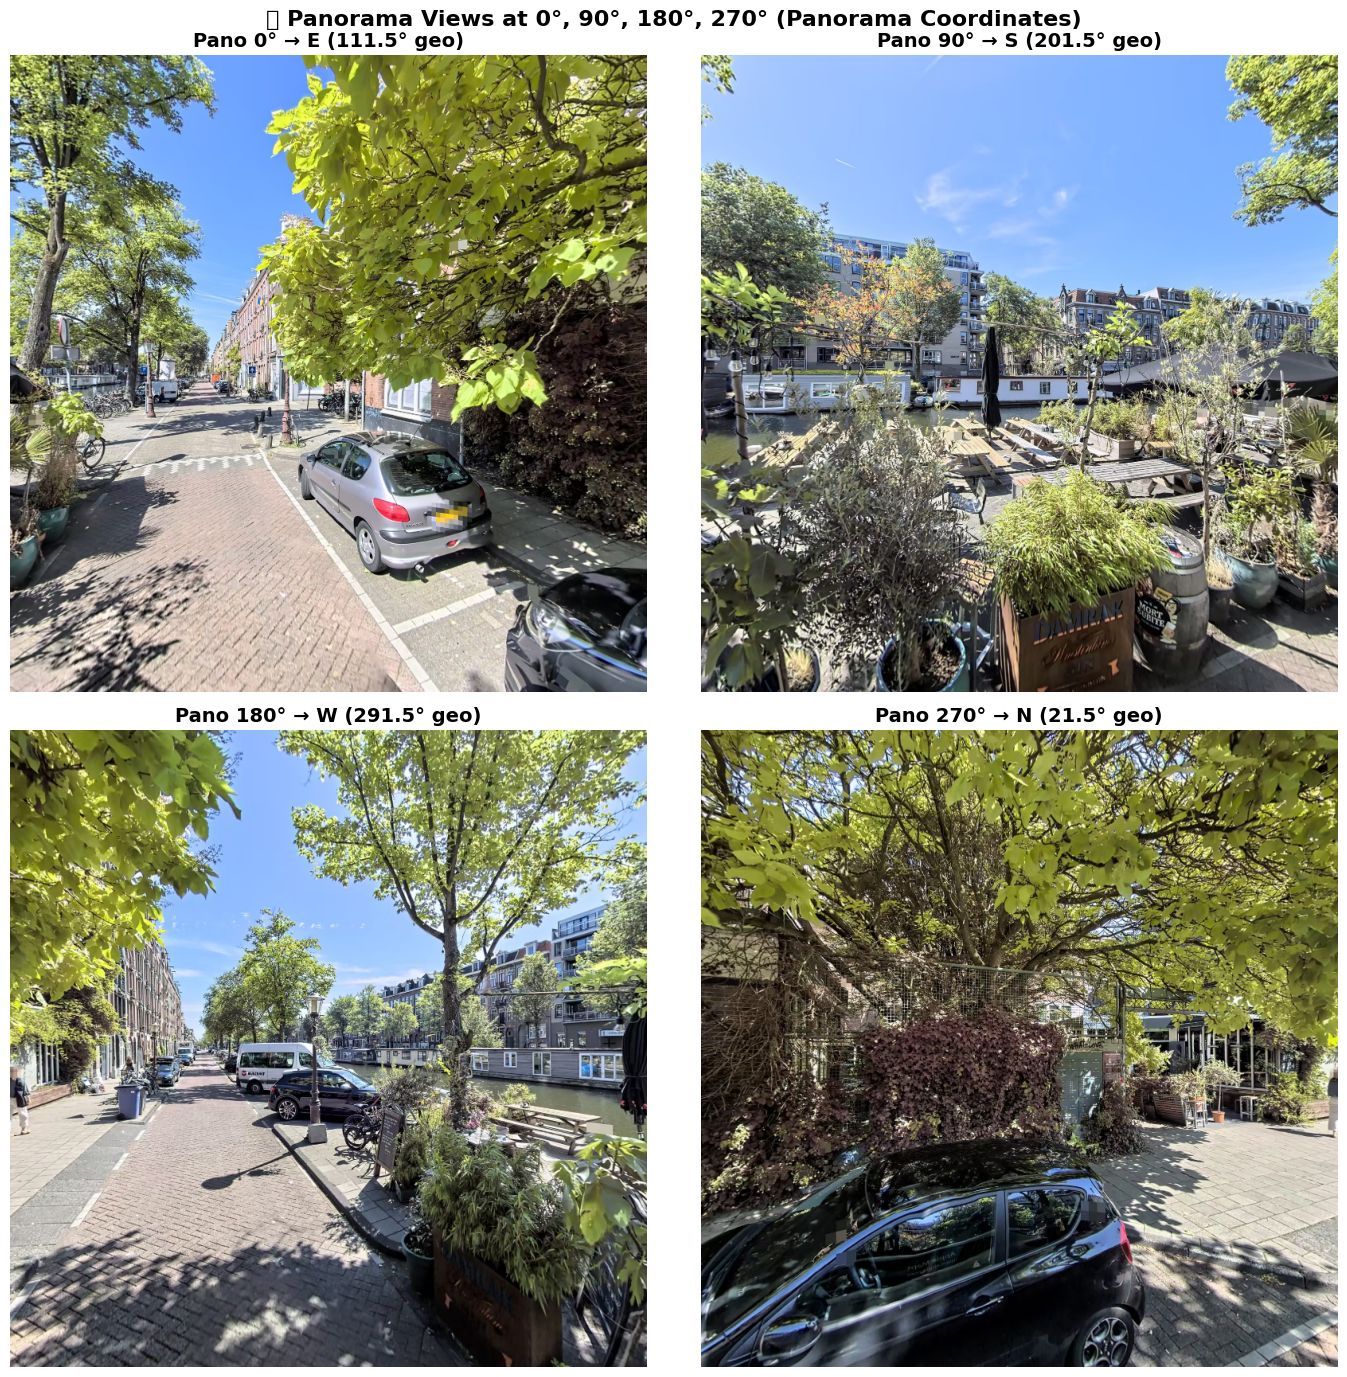

In [ ]:
# =============================================================================
# Display panorama with overlays at 0°, 90°, 180°, 270° (panorama coordinates)
# =============================================================================

if equirectangular:
    pano_headings = [0, 90, 180, 270]  # Panorama coordinate headings (panorama frame)
    
    # Get panorama heading in radians (direction the pano center is facing)
    pano_heading_rad_raw = metadata.get('heading') if metadata else None
    pano_source = metadata.get('source', 'streetview') if metadata else 'streetview'
    
    # Convert heading to CW geographic
    pano_heading_rad = None
    pano_heading_deg = None
    if pano_heading_rad_raw is not None:
        pano_heading_deg_raw = np.degrees(pano_heading_rad_raw)
        if pano_source == 'lookaround':
            pano_heading_deg = (360 - pano_heading_deg_raw) % 360
            print(f"📐 Lookaround heading: {pano_heading_deg_raw:.1f}° (CCW) → {pano_heading_deg:.1f}° (CW/geographic)")
        else:
            pano_heading_deg = pano_heading_deg_raw
            print(f"📐 Street View heading: {pano_heading_deg:.1f}° (geographic)")
        pano_heading_rad = np.radians(pano_heading_deg)
    
    # Calculate geographic headings for each panorama direction
    heading_labels = []
    if pano_heading_deg is not None:
        for pano_heading in pano_headings:
            # Geographic heading = panorama heading (geo CW) + panorama direction
            geo_heading = (pano_heading_deg + pano_heading) % 360
            
            # Determine cardinal direction name
            if geo_heading < 22.5 or geo_heading >= 337.5:
                dir_name = "N"
            elif geo_heading < 67.5:
                dir_name = "NE"
            elif geo_heading < 112.5:
                dir_name = "E"
            elif geo_heading < 157.5:
                dir_name = "SE"
            elif geo_heading < 202.5:
                dir_name = "S"
            elif geo_heading < 247.5:
                dir_name = "SW"
            elif geo_heading < 292.5:
                dir_name = "W"
            else:
                dir_name = "NW"
            
            heading_labels.append(f'Pano {pano_heading}° → {dir_name} ({geo_heading:.1f}° geo)')
    else:
        # Fallback if no panorama heading available
        heading_labels = ['Pano 0°', 'Pano 90°', 'Pano 180°', 'Pano 270°']
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 14))
    axes = axes.flatten()
    
    for ax, heading, label in zip(axes, pano_headings, heading_labels):
        # Convert pano-frame heading to geographic heading using pano_heading_deg
        if pano_heading_deg is not None:
            geo_heading = (pano_heading_deg + heading) % 360
        else:
            geo_heading = heading
        perspective = extract_perspective_view(
            equirectangular, geo_heading, fov=90, size=(800, 800),
            panorama_heading_rad=pano_heading_rad,
            source=pano_source,
        )
        ax.imshow(perspective)
        ax.set_title(label, fontsize=14, fontweight='bold')
        ax.axis('off')
    
    plt.suptitle('🧭 Panorama Views at 0°, 90°, 180°, 270° (Panorama Coordinates)', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print("No panorama available to display.")


In [8]:
# =============================================================================
# Calculate bearing from panorama to input location
# =============================================================================

if metadata:
    pano_lat = metadata['lat']
    pano_lng = metadata['lng']
    
    # Calculate bearing from panorama to input location
    bearing_to_input = calculate_bearing(pano_lat, pano_lng, INPUT_LAT, INPUT_LNG)
    
    print(f"\n🧭 BEARING CALCULATION")
    print(f"   From: Panorama ({pano_lat:.6f}, {pano_lng:.6f})")
    print(f"   To:   Input ({INPUT_LAT:.6f}, {INPUT_LNG:.6f})")
    print(f"   ➡️  Bearing: {bearing_to_input:.1f}°")
    
    # Determine cardinal direction
    if bearing_to_input < 22.5 or bearing_to_input >= 337.5:
        direction = "N (North)"
    elif bearing_to_input < 67.5:
        direction = "NE (Northeast)"
    elif bearing_to_input < 112.5:
        direction = "E (East)"
    elif bearing_to_input < 157.5:
        direction = "SE (Southeast)"
    elif bearing_to_input < 202.5:
        direction = "S (South)"
    elif bearing_to_input < 247.5:
        direction = "SW (Southwest)"
    elif bearing_to_input < 292.5:
        direction = "W (West)"
    else:
        direction = "NW (Northwest)"
    
    print(f"   📍 Direction: {direction}")
else:
    bearing_to_input = None
    print("No panorama metadata available for bearing calculation.")



🧭 BEARING CALCULATION
   From: Panorama (52.362846, 4.862100)
   To:   Input (52.362756, 4.862122)
   ➡️  Bearing: 171.4°
   📍 Direction: S (South)


In [ ]:
# =============================================================================
# Display map with bearing angle visualization
# =============================================================================

if metadata and bearing_to_input is not None:
    pano_lat = metadata['lat']
    pano_lng = metadata['lng']
    
    # Create map centered on panorama
    m2 = folium.Map(location=[pano_lat, pano_lng], zoom_start=18)
    
    # Add panorama location marker
    folium.Marker(
        [pano_lat, pano_lng],
        popup=f'Panorama<br>Bearing to input: {bearing_to_input:.1f}°',
        icon=folium.Icon(color='blue', icon='camera', prefix='fa'),
        tooltip='Panorama'
    ).add_to(m2)
    
    # Add input location marker
    folium.Marker(
        [INPUT_LAT, INPUT_LNG],
        popup=f'Input Location',
        icon=folium.Icon(color='red', icon='crosshairs', prefix='fa'),
        tooltip='Input'
    ).add_to(m2)
    
    # Draw bearing line (from panorama to input)
    folium.PolyLine(
        [[pano_lat, pano_lng], [INPUT_LAT, INPUT_LNG]],
        color='green',
        weight=4,
        opacity=0.9,
        tooltip=f'Bearing: {bearing_to_input:.1f}°'
    ).add_to(m2)
    
    # Draw North reference line (extend from panorama northward)
    # Calculate point 50m north of panorama
    north_offset = 0.0005  # approx 50m in lat degrees
    folium.PolyLine(
        [[pano_lat, pano_lng], [pano_lat + north_offset, pano_lng]],
        color='gray',
        weight=2,
        opacity=0.7,
        dash_array='5',
        tooltip='North (0°)'
    ).add_to(m2)
    
    # Add "N" label
    folium.Marker(
        [pano_lat + north_offset, pano_lng],
        icon=folium.DivIcon(
            html='<div style="font-size: 14pt; color: gray; font-weight: bold;">N</div>',
            icon_size=(20, 20),
            icon_anchor=(10, 20)
        )
    ).add_to(m2)
    
    # Add bearing angle label
    mid_lat = (pano_lat + INPUT_LAT) / 2
    mid_lng = (pano_lng + INPUT_LNG) / 2
    folium.Marker(
        [mid_lat, mid_lng],
        icon=folium.DivIcon(
            html=f'<div style="font-size: 12pt; color: green; font-weight: bold; background: white; padding: 2px 6px; border-radius: 4px; border: 1px solid green;">{bearing_to_input:.1f}°</div>',
            icon_size=(60, 30),
            icon_anchor=(30, 15)
        )
    ).add_to(m2)
    
    display(HTML(f"<h3>🧭 Map: Bearing from Panorama to Input = {bearing_to_input:.1f}°</h3>"))
    display(m2)
else:
    print("Cannot display bearing map - no panorama found.")


/var/folders/tl/40rt5yw54v150s3k8shhw5y00000gn/T/ipykernel_27574/153092542.py:43: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/blackmad/bench_finder/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


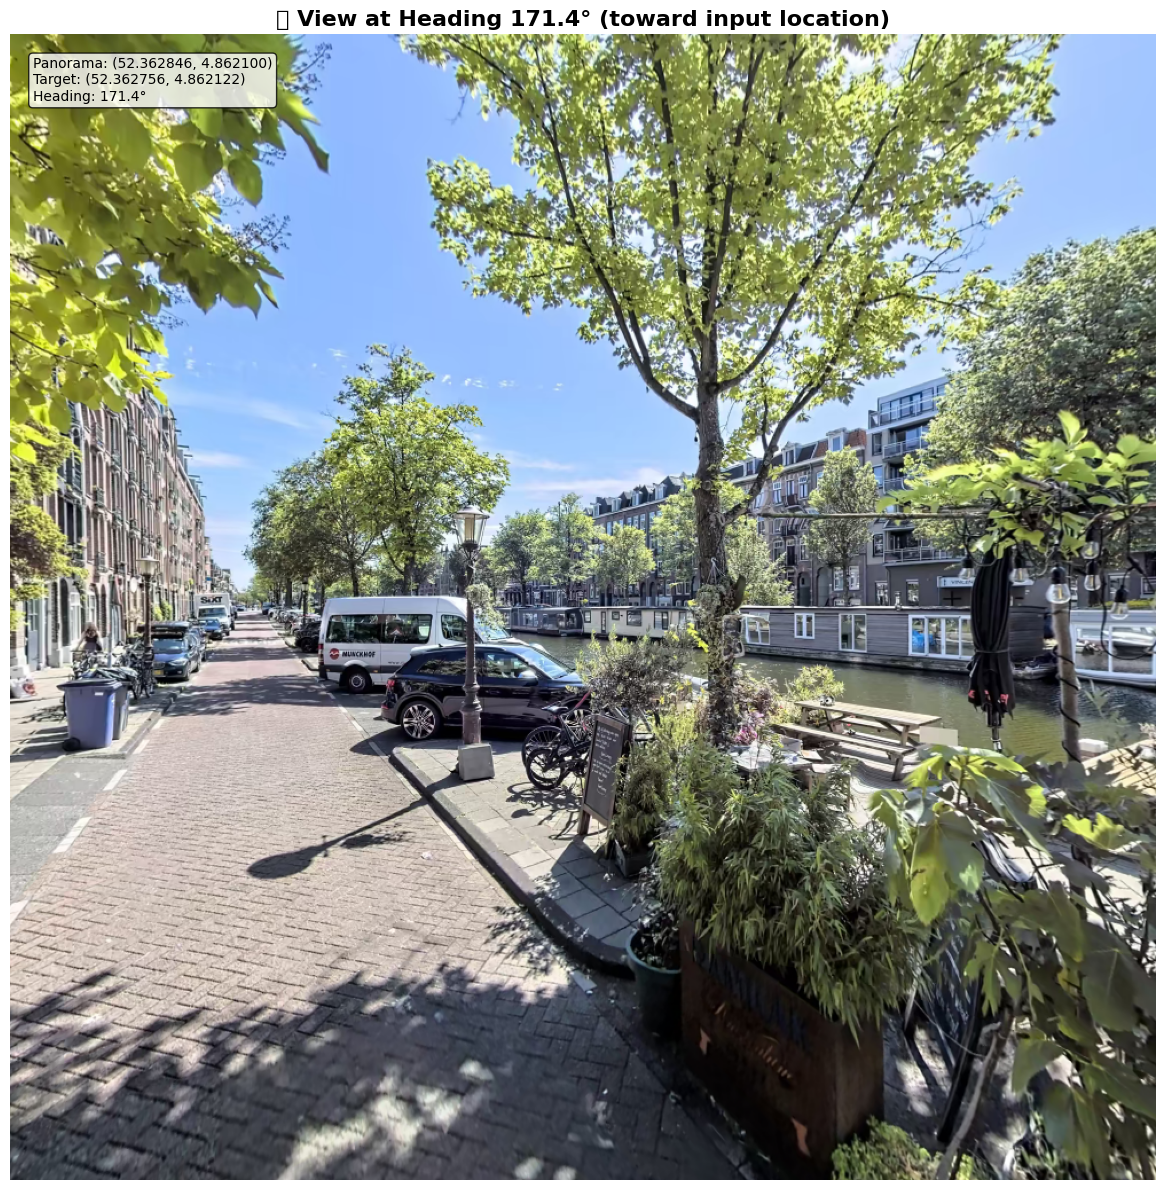


✅ This is the view from the panorama location looking toward your input coordinates!


In [ ]:
# =============================================================================
# Display the panorama at the calculated heading
# =============================================================================

if equirectangular and bearing_to_input is not None:
    # Get panorama heading and source
    pano_heading_rad_raw = metadata.get('heading') if metadata else None
    pano_source = metadata.get('source', 'streetview') if metadata else 'streetview'
    
    pano_heading_rad = None
    if pano_heading_rad_raw is not None:
        pano_heading_deg_raw = np.degrees(pano_heading_rad_raw)
        if pano_source == 'lookaround':
            pano_heading_deg = (360 - pano_heading_deg_raw) % 360
        else:
            pano_heading_deg = pano_heading_deg_raw
        pano_heading_rad = np.radians(pano_heading_deg)
    
    # Extract perspective view at the calculated bearing (accounting for pano heading)
    perspective_at_bearing = extract_perspective_view(
        equirectangular, 
        heading=bearing_to_input, 
        fov=90, 
        size=(1000, 1000),
        panorama_heading_rad=pano_heading_rad,
        source=pano_source,
    )
    
    # Display the perspective view
    fig, ax = plt.subplots(figsize=(12, 12))
    ax.imshow(perspective_at_bearing)
    ax.set_title(
        f'🎯 View at Heading {bearing_to_input:.1f}° (toward input location)',
        fontsize=16,
        fontweight='bold'
    )
    ax.axis('off')
    
    # Add bearing info text
    info_text = f"Panorama: ({metadata['lat']:.6f}, {metadata['lng']:.6f})\n"
    info_text += f"Target: ({INPUT_LAT:.6f}, {INPUT_LNG:.6f})\n"
    info_text += f"Heading: {bearing_to_input:.1f}°"
    
    ax.text(
        0.02, 0.98, info_text,
        transform=ax.transAxes,
        fontsize=10,
        verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
    )
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n✅ This is the view from the panorama location looking toward your input coordinates!")
else:
    print("Cannot display perspective view - no panorama or bearing available.")


In [11]:
# =============================================================================
# Summary
# =============================================================================

if metadata:
    print("\n" + "="*60)
    print("📋 SUMMARY")
    print("="*60)
    print(f"\n📍 Input Location:")
    print(f"   Latitude:  {INPUT_LAT}")
    print(f"   Longitude: {INPUT_LNG}")
    
    print(f"\n📸 Panorama Found:")
    print(f"   Latitude:  {metadata['lat']}")
    print(f"   Longitude: {metadata['lng']}")
    print(f"   Pano ID:   {metadata['pano_id']}")
    print(f"   Date:      {metadata['date']}")
    
    if bearing_to_input is not None:
        print(f"\n🧭 Calculated Bearing:")
        print(f"   From panorama → input: {bearing_to_input:.1f}°")
        
        distance = haversine_distance(INPUT_LAT, INPUT_LNG, metadata['lat'], metadata['lng'])
        print(f"\n📏 Distance: {distance:.1f} meters")
    
    print("\n" + "="*60)
else:
    print("\n❌ No panorama found for the input location.")



📋 SUMMARY

📍 Input Location:
   Latitude:  52.362756
   Longitude: 4.862122

📸 Panorama Found:
   Latitude:  52.36284640368089
   Longitude: 4.862099647522001
   Pano ID:   18044057293112774835
   Date:      2022-06-29 09:26:28.787000+00:00

🧭 Calculated Bearing:
   From panorama → input: 171.4°

📏 Distance: 10.2 meters

